In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer

In [4]:
data = pd.read_csv("real_estate_ads.csv")
data

# id - numer identyfikacyjny ogłoszenia
# market - czy rynek wtórny, czy nie (secondary lub primary)
# created_at_first - kiedy pierwszy raz zrobiono ogłoszenie
# created_at - kiedy ostatni raz zrobiono ogłoszenie
# district_lon, district_lat - 
# title - tytuł ogłoczenia
# description - treść ogłoszenia
# params - kolumna z dodatkowymi ukrytymi parametrami
# price - cena
# no_rooms - liczba pokoi
# m - ilość metrów kwadratowych
# price_per_m - cena za metr kwadratowy
# map_lon, map_lat - 
# params_dict


,id,market,created_at_first,created_at,district_lon,district_lat,title,description,params,price,no_rooms,m,price_per_m,map_lon,map_lat
0,49341,secondary,2018-01-04 13:11:05,2018-01-08 11:27:35,16.94080,52.38356,NaN,<p>Zapraszam do zapoznania się z ofertą sprzed...,price<=>price<br>price<=>289000<br>price[curre...,289000.0,3,48.000000,6020.83,16.959516,52.391494
1,261720,secondary,2018-01-15 19:12:07,2018-01-25 11:11:31,16.94080,52.38356,NaN,<p>Zapraszam do zapoznania się z ofertą sprzed...,price<=>price<br>price<=>379000<br>price[curre...,379000.0,3,61.000000,6213.11,16.950743,52.380535
2,50441,secondary,2018-01-04 13:53:29,2018-01-11 05:55:12,16.94080,52.38356,Rataje Nowe Miasto Niski Blok,<p>Weychan Nieruchomości Monika Hałas - Kurcza...,price<=>price<br>price<=>339000<br>price[curre...,339000.0,3,63.000000,5380.95,16.945860,52.393188
3,203518,secondary,2018-01-12 11:10:57,2018-01-30 14:38:39,16.94080,52.38356,"Mieszkanie 3 pokojowe blisko tramwaju, Poznań os.",<p>Oferuję na sprzedaż jasne i zadbane mieszka...,price<=>price<br>price<=>330000<br>price[curre...,330000.0,3,59.200001,5574.32,16.980279,52.391129
4,5,secondary,2018-01-02 11:34:51,2018-01-18 14:22:29,16.94080,52.38356,"Inwestycja -rondo Rataje student AWF,POLITECHNIKA",<p><strong>Dwa pokoje na niskim piętrze tuż pr...,price<=>price<br>price<=>259000<br>price[curre...,259000.0,2,38.000000,6815.79,16.950027,52.395861
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13740,9595517,primary,2021-01-25 16:28:24,2021-01-25 16:28:42,16.94080,52.38356,"DEWELOPER: 25,98m2, kawalerka, Rataje, Wagrowska",<p><strong>*NOWA INWESTYCJA NA UL. WAGROWSKIEJ...,price<=>price<br>price<=>231614<br>price[curre...,231614.0,1,25.980000,8915.09,16.940800,52.383560
13741,9589026,primary,2021-01-23 13:31:54,2021-01-23 13:32:14,16.94080,52.38356,"BIURO SPRZEDAŻY: 3pok., 47,37 m2, Rataje,Wagro...",<p><strong><u>NOWY ETAP JUŻ W SPRZEDAŻY</u></s...,price<=>price<br>price<=>364000<br>price[curre...,364000.0,3,47.369999,7684.19,16.940800,52.383560
13742,9592654,primary,2021-01-25 08:58:31,2021-01-25 08:58:48,16.94080,52.38356,SŁONECZNE M-3 Na I Piętrze przy Malcie,<ul>\r\n<li><strong>Kupuj bezpośrednio od dewe...,price<=>price<br>price<=>485450<br>price[curre...,485450.0,3,61.990002,7831.10,16.964770,52.394719
13743,9573742,secondary,2021-01-19 17:11:04,2021-01-25 12:31:44,16.96521,52.38044,Mieszkanie Nowe Żegrze,<p><br/>Cały projekt będzie składał się z 4 bu...,price<=>price<br>price<=>437360<br>price[curre...,437360.0,3,61.599998,7100.00,16.965488,52.381074


In [3]:
data.shape # (13745 obserwacji i 15 zmiennych) 
data.isna().sum() # dla district_lon i district_lat mamy 187 brakujących wartości
# dla title mamy 927 brakujących wartości
data.dropna()
# pozostałe zmienne nie mają zadnych braków

# usuwamy wiersze z brakującymi wartościami
data_clean = data.dropna()
data_clean = data_clean.drop(columns = "id") # usuwamy kolumnę id, nie będzie ona potrzebna
data_clean.shape
# zostaje 12639 obserwacji i 14 zmiennych

(12639, 14)

In [4]:
# zamieniamy typ danych na datetime w kolumnie created_at i sortujemy dane od najnowszych do najstarszych
data_clean['created_at'] = pd.to_datetime(data_clean['created_at'])
data_clean = data_clean.sort_values(by='created_at', ascending=False)
# te same ogłoszenia będziemy identyfikować za pomocą danych lokalizacyjnych, liczby pokoi i metrów kwadratowych
identyfikatory = ['map_lat', 'map_lon', 'm', 'no_rooms', 'district_lon', 'district_lat']
# keep='first' sprawia, e zostanie tylko pierwszy wiersz dla danej kombinacji identyfikatorów
df_clean = data_clean.drop_duplicates(subset=identyfikatory, keep='first')

print(f"Liczba ofert przed czyszczeniem: {len(data_clean)}") # 12639
print(f"Liczba ofert po usunięciu duplikatów: {len(df_clean)}") # 11054
# usunęliśmy 1585 ogłoszeń

Liczba ofert przed czyszczeniem: 12639
Liczba ofert po usunięciu duplikatów: 11054


In [5]:
# tworzymy zmienną długość opisów
dlugosc_opisow = df_clean['description'].fillna('').apply(len)
display(dlugosc_opisow.describe().round(0))
df_clean['desc_length'] = dlugosc_opisow

count    11054.0
mean      1955.0
std        883.0
min         60.0
25%       1338.0
50%       1812.0
75%       2448.0
max       9452.0
Name: description, dtype: float64

In [6]:
# zmienna no_rooms
df_clean['no_rooms'].unique() # zawiera ona wartości ['3', '1', '2', '4', '5', '6', '7', 'more']
# 6 obserwacji przyjmuje wartość more, zamieniamy je na wartość 8
df_clean['no_rooms'] = df_clean['no_rooms'].replace('more', '8')
df_clean['no_rooms'] = df_clean['no_rooms'].astype('int64') # zmieniamy typ danych na int

In [7]:
# kodujemy market jako zmienną 'market_secondary' o wartościach True (secondary) i False (primary)
df_clean['market'] = df_clean['market'] == 'secondary'

## Obserwacje odstające

In [8]:
# statystyka opisowa do danych numerycznych
data_num = df_clean[['price', 'no_rooms', 'm', 'price_per_m', 'desc_length']].describe().round(2)
data_num

,price,no_rooms,m,price_per_m,desc_length
count,11054.00,11054.00,11054.00,11054.00,11054.00
mean,374061.32,2.49,74.29,7566.76,1954.66
std,391629.53,0.87,2539.10,7832.11,883.15
min,35000.00,1.00,15.20,1.00,60.00
25%,289000.00,2.00,38.00,6800.00,1338.00
50%,339000.00,2.00,48.07,7550.00,1812.00
75%,405000.00,3.00,58.03,8159.81,2447.75
max,38606600.00,8.00,267000.00,821417.02,9452.00


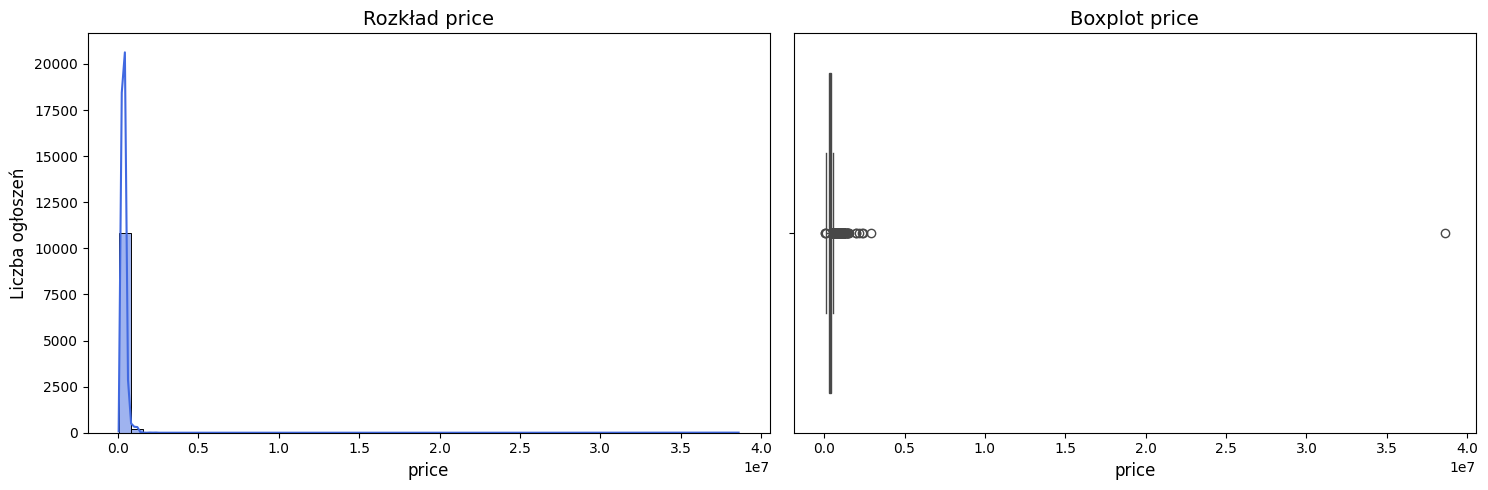

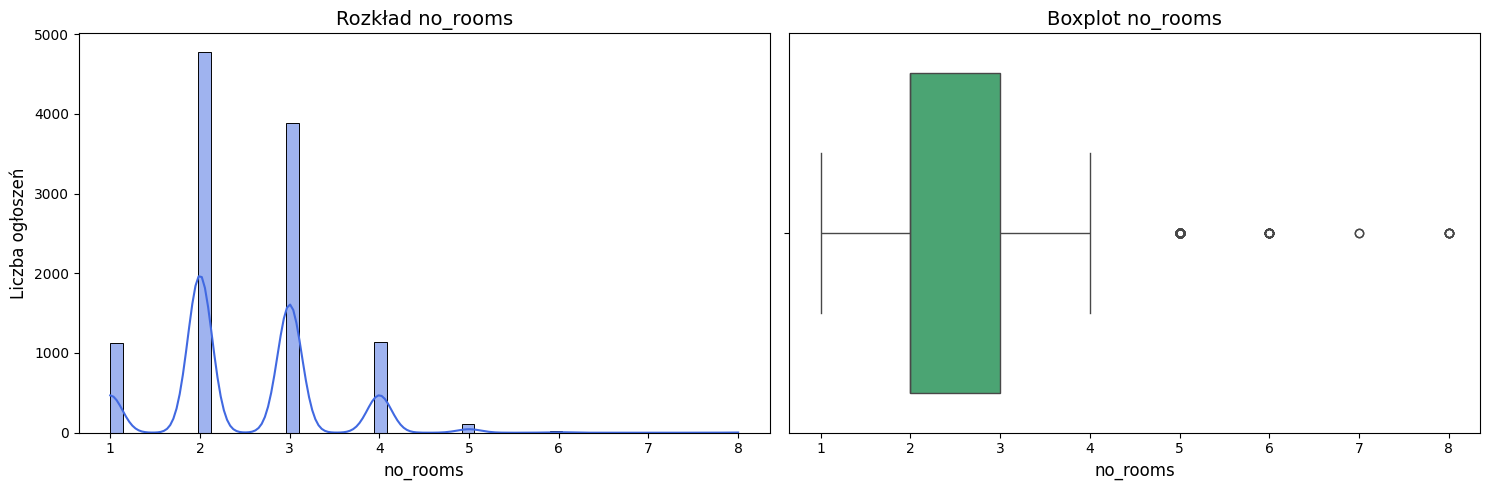

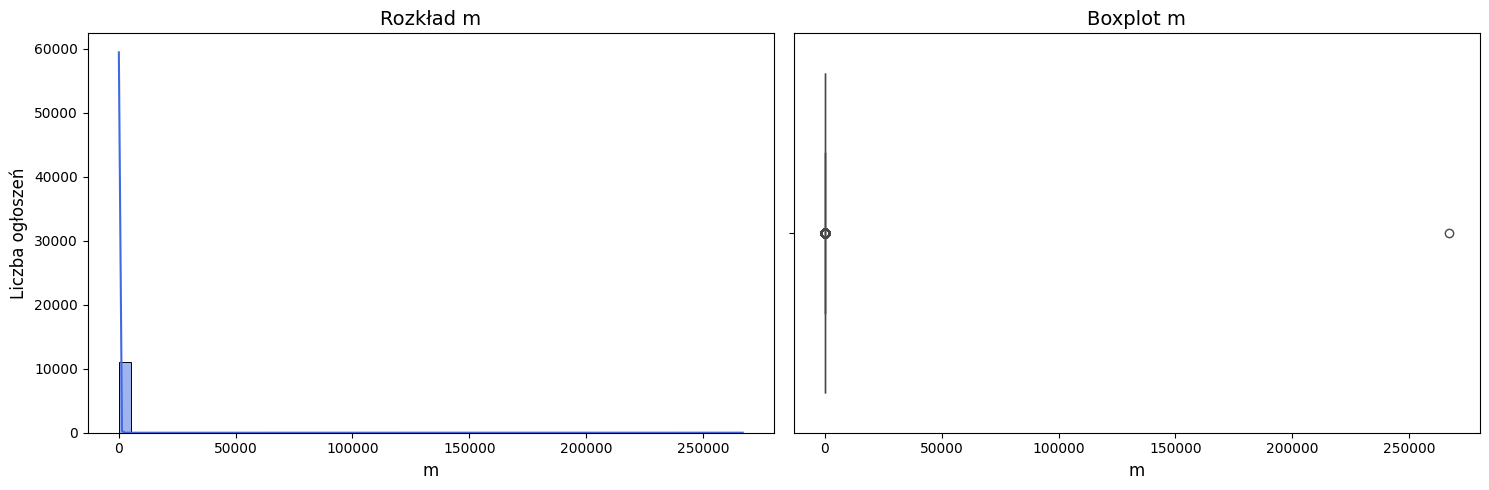

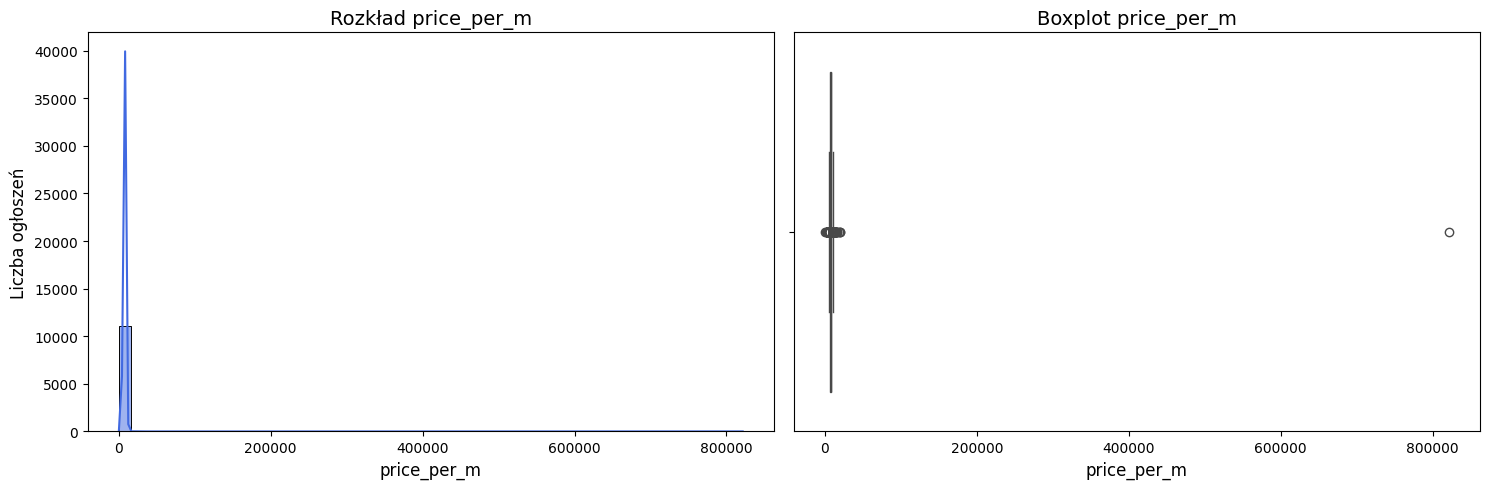

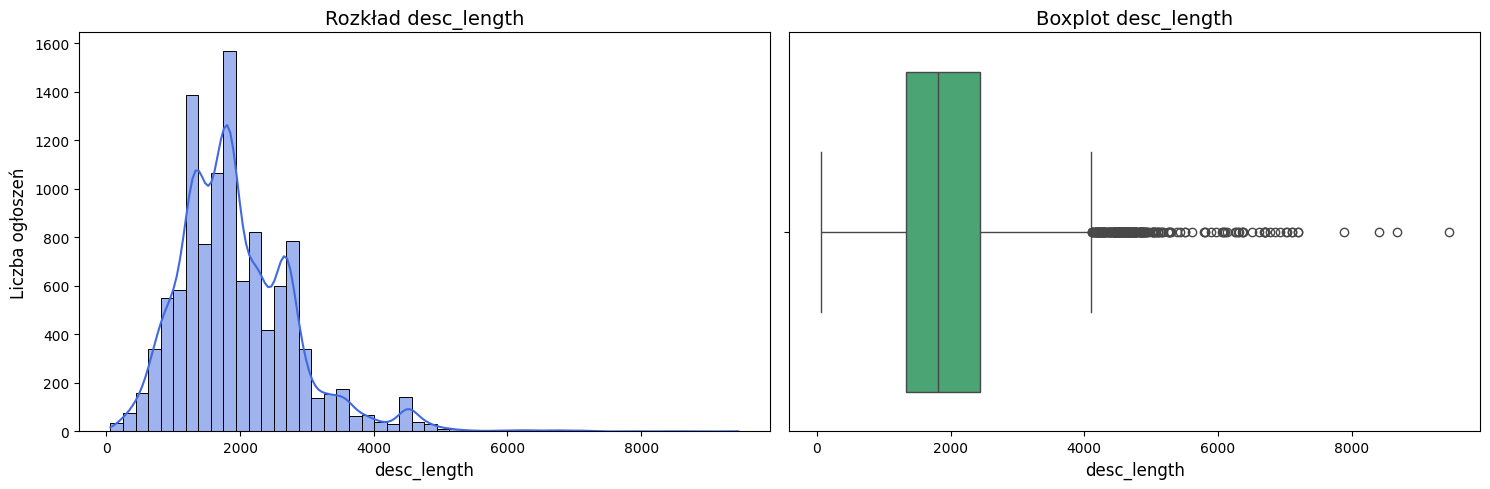

In [9]:
for kolumna in data_num:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.histplot(df_clean[kolumna].dropna(), bins=50, kde=True, ax=axes[0], color='royalblue')
    axes[0].set_title(f'Rozkład {kolumna}', fontsize=14)
    axes[0].set_xlabel(kolumna, fontsize=12)
    axes[0].set_ylabel('Liczba ogłoszeń', fontsize=12)
    
    sns.boxplot(x=df_clean[kolumna].dropna(), ax=axes[1], color='mediumseagreen')
    axes[1].set_title(f'Boxplot {kolumna}', fontsize=14)
    axes[1].set_xlabel(kolumna, fontsize=12)
    
    plt.tight_layout()
    plt.show()

In [10]:
# Wykrywamy outliery
def get_outlier_mask(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return (df[column] < lower_bound) | (df[column] > upper_bound)

mask_rooms = get_outlier_mask(df_clean, 'no_rooms')
mask_m = get_outlier_mask(df_clean, 'm')
mask_price_m = get_outlier_mask(df_clean, 'price_per_m')
mask_price = get_outlier_mask(df_clean, 'price')
total_outliers_mask = mask_rooms | mask_m | mask_price_m | mask_price

df_clean = df_clean[~total_outliers_mask] # usuwamy outliery
print(f"Liczba usuniętych wierszy łącznie {total_outliers_mask.sum()}") # 959

Liczba usuniętych wierszy łącznie 929


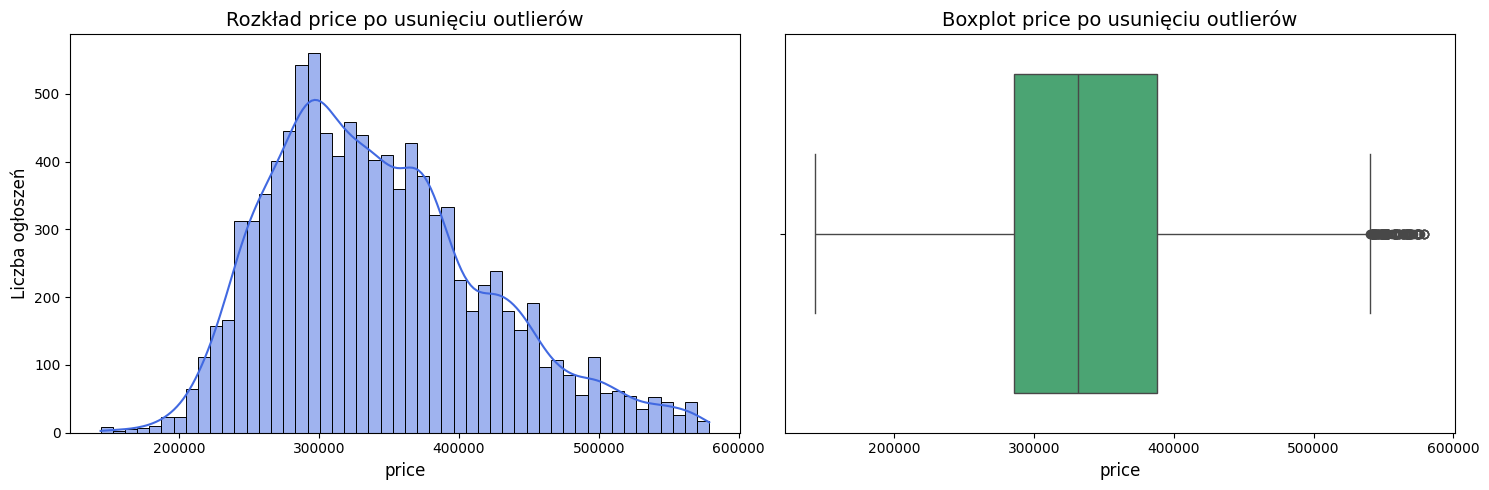

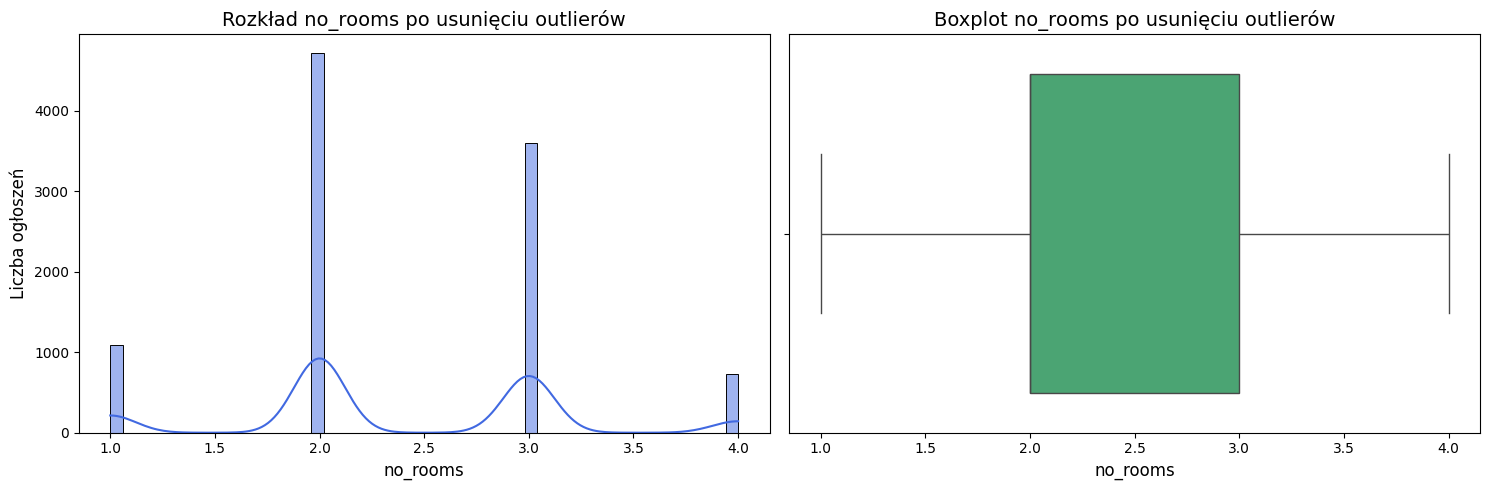

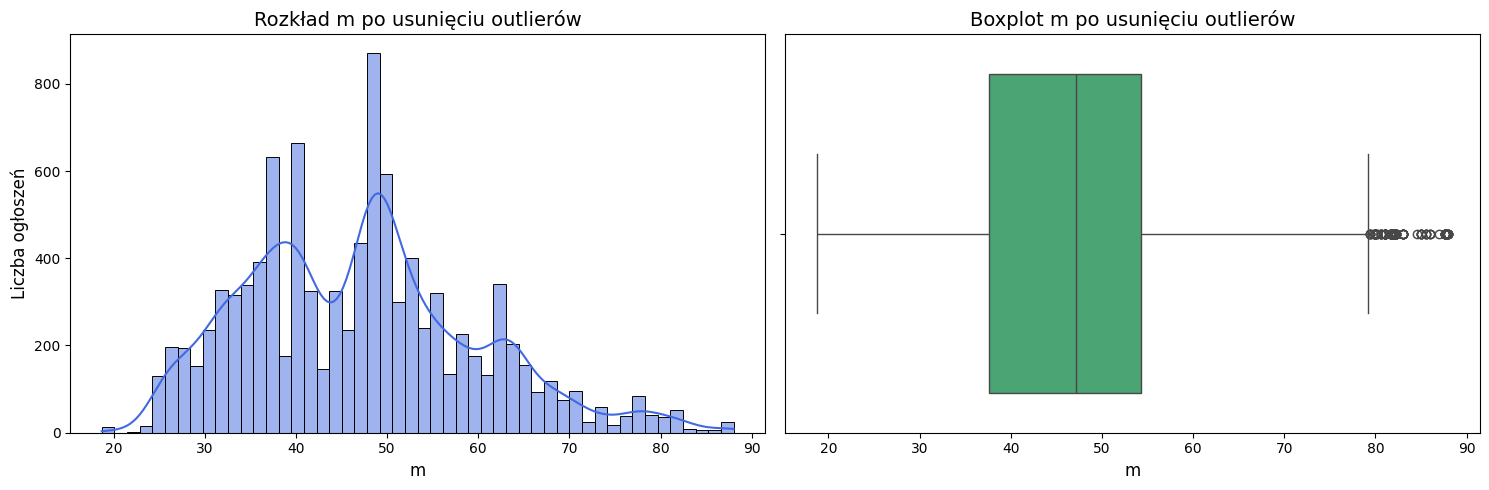

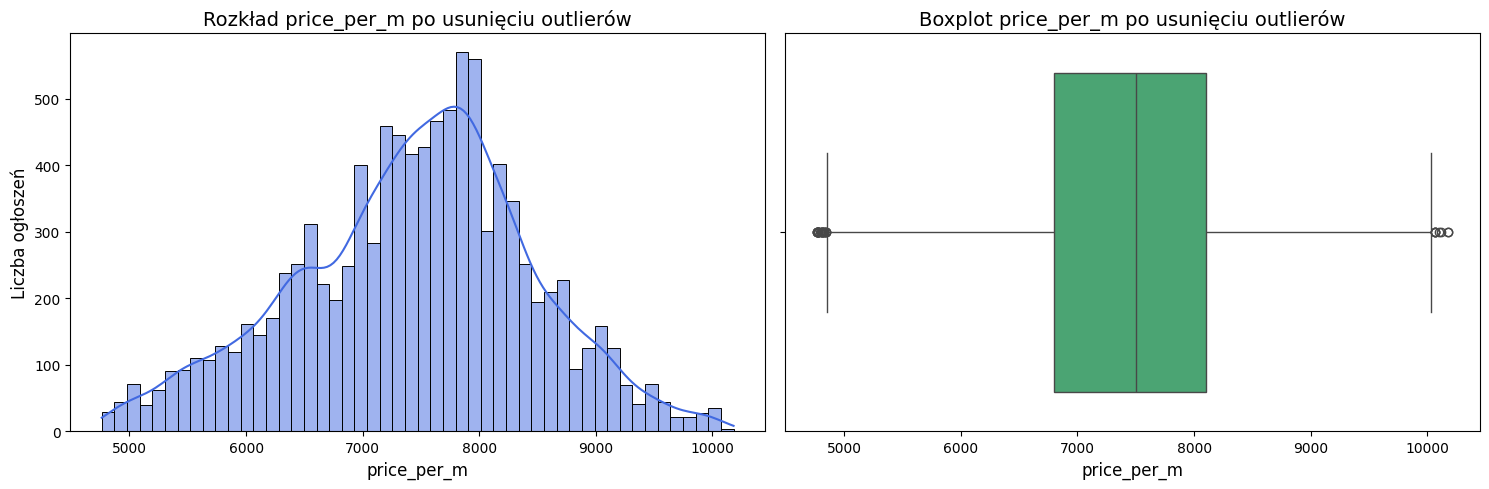

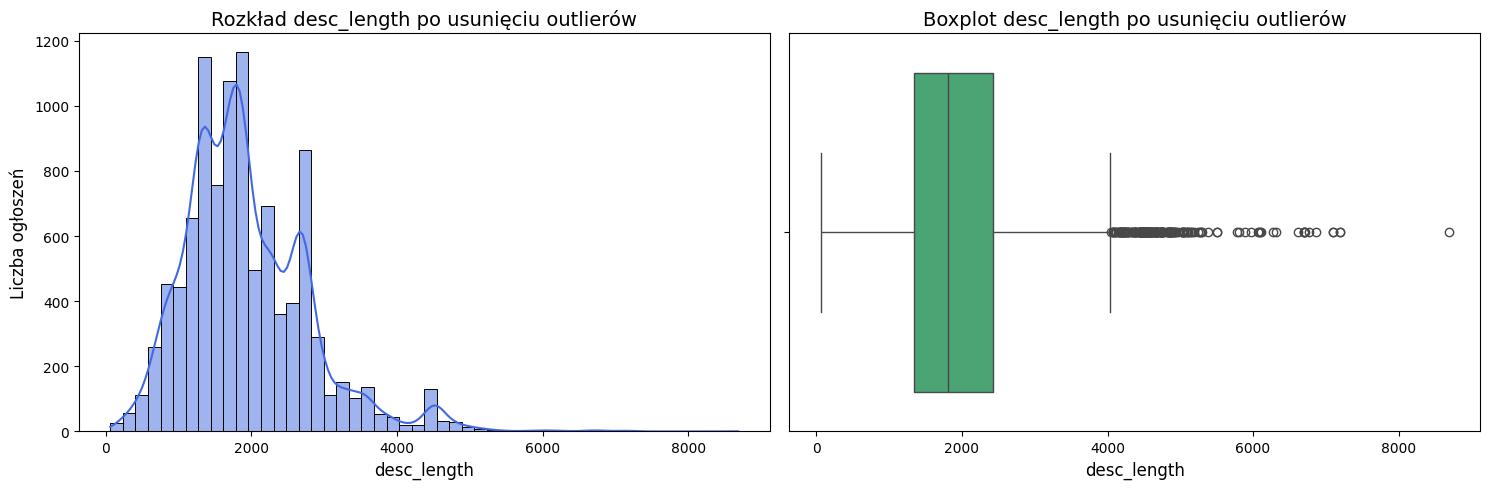

In [11]:
for kolumna in data_num:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.histplot(df_clean[kolumna].dropna(), bins=50, kde=True, ax=axes[0], color='royalblue')
    axes[0].set_title(f'Rozkład {kolumna} po usunięciu outlierów', fontsize=14)
    axes[0].set_xlabel(kolumna, fontsize=12)
    axes[0].set_ylabel('Liczba ogłoszeń', fontsize=12)
    
    sns.boxplot(x=df_clean[kolumna].dropna(), ax=axes[1], color='mediumseagreen')
    axes[1].set_title(f'Boxplot {kolumna} po usunięciu outlierów', fontsize=14)
    axes[1].set_xlabel(kolumna, fontsize=12)
    
    plt.tight_layout()
    plt.show()

## Kolumna params

In [12]:
def expand_params_to_separate_df(df, params_col='params'):
    expanded_list = []
    for row in df[params_col]:
        row_dict = {}
        if pd.notna(row):
            pairs = row.split('<br>') # rozdzielamy parametry po znaczniku <br>
            for pair in pairs:
                if '<=>' in pair:
                    key, value = pair.split('<=>', 1)
                    if key != value:
                        row_dict[key] = value
        expanded_list.append(row_dict)
    
    params_df = pd.DataFrame(expanded_list)
    original_cols = df.columns.tolist()
    new_cols = [col for col in params_df.columns if col not in original_cols]
    return params_df[new_cols]

df_params = expand_params_to_separate_df(df_clean)
df_params = df_params.drop(columns=['rooms_num'])


In [13]:
wartosci_do_usuniecia = ['', ' ', 'NaN', 'nan', 'None', 'brak informacji']
df_params = df_params.replace(wartosci_do_usuniecia, np.nan)

df_params.isna().sum()

price[currency]           0
remote_services        9411
building_type          1499
floor_no                218
building_floors_num    1051
building_material      5382
windows_type           3850
heating                3035
build_year             3964
construction_status    3098
rent                   7210
rent[currency]          323
building_ownership     3311
free_from              8743
media_types            2634
security_types         2744
equipment_types        3794
extras_types            853
dtype: int64

In [ ]:
# kolumna remote services
df_params['remote_services'] # przyjmuje wartości 1 lub Nan
# zdalne monitorowanie i zarządzanie mieszkaniem, zakładamy, ze tam gdzie przyjmuje wartość Nan to nie ma takiej moliwości
# Nan/puste imputujemy jako 0
df_params['remote_services'] = (df_params['remote_services'].fillna(0).astype(int))

#############################

# kolumna floor_no
df_params['floor_no'].unique() # 14 wartości [floor_1, ..., cellar, ground_floor, ]
# chcemy zakodować zmienne [floor_1, ..., cellar, ground_floor, ] jako numeryczne

def clean_floor_no(df_p):
    mapping = {'ground_floor': '0', 'cellar': '-1'}
    df_p['floor_no'] = df_p['floor_no'].replace(mapping)
    df_p['floor_no'] = df_p['floor_no'].astype(str).str.extract(r'(-?\d+)').astype(float)
    return df_p

df_params = clean_floor_no(df_params)
df_params['floor_no'].isna().sum() # mamy 233 braków, które usuniemy

#################################################################

# kolumna building_type
df_params['building_type'].unique() # ['block', '', 'apartment', 'ribbon', 'tenement', 'house']

def clean_building(df_p):
    mapping = {'block': '0', 'apartment': '1', 'ribbon': '2', 'tenement': '3', 'house': '4'}
    df_p['building_type'] = df_p['building_type'].map(mapping)
    return df_p

df_params = clean_building(df_params)
df_params['building_type'].isna().sum() # mamy 1610 braków

######################################################

# kolumna building_floors_num
df_params['building_floors_num'].unique() # podane jako liczby, ale mamy zmienną Nan
df_params['building_floors_num'].isna().sum() # mamy 1117 braków

np.int64(1051)

In [15]:
# imputacja modą
mode_floor = df_params['floor_no'].mode()[0]
mode_building_type = df_params['building_type'].mode()[0]
mode_building_floors = df_params['building_floors_num'].mode()[0]

df_params['floor_no'] = df_params['floor_no'].fillna(mode_floor)
df_params['building_type'] = df_params['building_type'].fillna(mode_building_type)
df_params['building_floors_num'] = df_params['building_floors_num'].fillna(mode_building_floors)

In [16]:
# kolumna extras_types
df_params['extras_types'].unique()

# z uwagi na typ danych przeprowadzamy One-HotEncoding
# jeśli nie mamy adnych wartości, to będziemy zamieniać na 0

def process_extras(df_p, col_name='extras_types'):
    extras_series = df_p[col_name].fillna('') # zamieniamy Nany na puste
    extras_dummies = extras_series.str.get_dummies(sep='<->')
    extras_dummies = extras_dummies.add_prefix('extras_')
    return extras_dummies

df_extras_encoded = process_extras(df_params)
df_extras_encoded.columns.tolist() # powstały nowe zmienne
df_extras_encoded.head()


# pojawia duzo nowych kolumn (11)
# sprawdzimy korelację między zmiennymi, niektóre udogodnienia moze występują zawsze razem?

df_extras_encoded = df_extras_encoded.drop(columns = 'extras_0')
df_extras_encoded.sum() # ostatecznie mamy 11 nowych kolumn, które dodamy do zmiennych

extras_                     853
extras_air_conditioning      81
extras_balcony             6689
extras_basement            3344
extras_garage              3969
extras_garden              1053
extras_lift                6846
extras_separate_kitchen    2041
extras_terrace             1672
extras_two_storey            35
extras_usable_room          714
dtype: int64

Ze zmiennej params wykstraktowaliśmy 18 zmiennych, które nie pokrywały się z naszymi danymi.

Kolumna 'price[currency]' potwierdza, ze wszystkie ceny mieszkań są w PLN, jednak nie będzie ona nam potrzebna w modelu.

Zmienna 'remote_services' została imputowana i będzie dodana do modelu.

Zmienna 'floor_no' będzie dodana do modelu, ma około 200 braków.

Zmienne ['building_floors_num', 'building_type']

Zmienna 'extras_types' została rozdzielona za pomocą One-Hot Encoding i będzie dodana do modelu jako 10 nowych kolumn.

Reszta zmiennych nie będzie uzyta w modelu (m. in. przez ilość braków).

In [17]:
params_data = df_params[['remote_services', 'floor_no', 'building_type', 'building_floors_num']]
params_data = pd.concat([params_data, df_extras_encoded], axis=1)
params_data

,remote_services,floor_no,building_type,building_floors_num,extras_,extras_air_conditioning,extras_balcony,extras_basement,extras_garage,extras_garden,extras_lift,extras_separate_kitchen,extras_terrace,extras_two_storey,extras_usable_room
0,0,3.0,0,4,0,0,1,1,0,0,0,1,0,0,1
1,0,7.0,0,10,0,0,0,1,0,0,0,0,0,0,0
2,1,0.0,0,5,0,0,1,0,0,0,1,0,0,0,0
3,1,4.0,0,5,0,0,1,0,0,0,1,0,0,0,0
4,0,4.0,0,9,0,0,0,1,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10120,0,1.0,0,10,0,0,0,1,0,0,0,0,0,0,0
10121,0,1.0,0,10,0,0,0,1,0,0,0,0,0,0,0
10122,0,1.0,0,4,0,0,0,1,0,0,0,0,0,0,0
10123,0,3.0,0,4,0,0,1,1,0,0,0,0,0,0,0


## Dane geograficzne

map_lon, map_lat - współrzędne geograficzne (dokładna lokalizacja)
district_lon, district_lat - lokalizacja uogólniona

In [18]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

In [19]:
# centrum Poznania to (52.2420, 16.5525)
# liczymy odległość nieruchomości od centrum (w km)
city_center_lat = 52.2420
city_center_lon = 16.5525

df_clean['distance_to_center'] = haversine(df_clean['map_lat'], df_clean['map_lon'],
    city_center_lat, city_center_lon)

In [ ]:
# odległość od dworca Poznań Główny (52.4010, 16.9080)
station_lat = 52.4010
station_lon = 16.9080

df_clean['distance_to_station'] = haversine(df_clean['map_lat'],df_clean['map_lon'],station_lat,station_lon)

## Dane lingwistyczne

In [21]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'\s+', ' ', text) # usuwamy tagi HTML
    text = re.sub(r'[^a-zA-ZąęćłńóśźżĄĘĆŁŃÓŚŹŻ\s]', ' ', text) # usuwamy znaki interpunkcyjne 
    text = text.lower().strip() # małe litery
    return text

df_clean['clean_description'] = df_clean['description'].apply(clean_text)
df_clean['clean_title'] = df_clean['title'].apply(clean_text)

## Dane do modelowania

In [ ]:
# dane do modelowania
dane_mod = df_clean.drop(columns = ['params', 'price', 'title', 'description'])
dane_mod = dane_mod.reset_index(drop=True)
dane_mod = pd.concat([dane_mod, params_data], axis=1)
# ostatecznie otrzymujemy 10125 obserwacji i 30 zmiennych

In [23]:
dane_mod.to_csv('../data/processed/data_processed.csv', index=False)